# Trees:
My sub-metric is the best **urban forest**. A neighborhood is best if it has lots of trees, they are healthy, and each one gives back a lot of value.

Here I am importing my data set

In [2]:
import pandas as pd

df = pd.read_csv("Treesdata.csv")
df.head()

,_id,id,address_number,street,common_name,scientific_name,height,width,growth_space_length,growth_space_width,...,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,754166088,7428.0,MONTICELLO ST,Stump,Stump,0.0,0.0,10.0,2.0,...,Homewood North,9.0,13.0,4.200313e+10,2.0,13.0,5.0,3-17,40.458169,-79.889724
1,2,1946899269,220.0,BALVER AVE,Linden: Littleleaf,Tilia cordata,0.0,0.0,99.0,99.0,...,Oakwood,2.0,28.0,4.200356e+10,5.0,28.0,6.0,1-19,40.429269,-80.067868
2,3,1431517397,2822.0,SIDNEY ST,Maple: Red,Acer rubrum,22.0,6.0,6.0,3.0,...,South Side Flats,3.0,16.0,4.200316e+10,3.0,16.0,3.0,4-24,40.426797,-79.965035
3,4,994063598,608.0,SUISMON ST,Maple: Freeman,Acer x freemanii,25.0,10.0,3.0,3.0,...,East Allegheny,1.0,23.0,4.200356e+10,1.0,23.0,1.0,1-6,40.455503,-79.999276
4,5,1591838573,1135.0,N NEGLEY AVE,Maple: Norway,Acer platanoides,52.0,13.0,99.0,99.0,...,Highland Park,7.0,11.0,4.200311e+10,2.0,11.0,5.0,3-9,40.476667,-79.924106


In [3]:
trees.columns

Index(['_id', 'id', 'address_number', 'street', 'common_name',
       'scientific_name', 'height', 'width', 'growth_space_length',
       'growth_space_width', 'growth_space_type', 'diameter_base_height',
       'stems', 'overhead_utilities', 'land_use', 'condition',
       'stormwater_benefits_dollar_value', 'stormwater_benefits_runoff_elim',
       'property_value_benefits_dollarvalue',
       'property_value_benefits_leaf_surface_area',
       'energy_benefits_electricity_dollar_value',
       'energy_benefits_gas_dollar_value',
       'air_quality_benfits_o3dep_dollar_value',
       'air_quality_benfits_o3dep_lbs',
       'air_quality_benfits_vocavd_dollar_value',
       'air_quality_benfits_vocavd_lbs',
       'air_quality_benfits_no2dep_dollar_value',
       'air_quality_benfits_no2dep_lbs',
       'air_quality_benfits_no2avd_dollar_value',
       'air_quality_benfits_no2avd_lbs',
       'air_quality_benfits_so2dep_dollar_value',
       'air_quality_benfits_so2dep_lbs',
       'a

Here I get all of the data into columns for how they are described. The file also has stumps, empty planting sites and dead trees, so I throw those out first and only keep real living trees that have a neighborhood

In [4]:
not_a_tree = trees.common_name.str.contains("Stump|Vacant Site|Unknown", na=False)
live = trees[~not_a_tree & trees.neighborhood.notna() & (trees.condition != "Dead")].copy()
live["healthy"] = live.condition.isin(["Good", "Very Good", "Excellent"])
live["rated"] = live.condition.notna()
len(live)

7374

Now I have to group the data that I need which is the neighborhoods and then measure three things for each one: how many trees, what share are healthy, and the average yearly dollar benefit per tree. I drop neighborhoods under 100 trees so a tiny sample can't win

In [6]:
g = live.groupby("neighborhood")
tn = pd.DataFrame({
    "n_trees": g.size(),
    "pct_healthy": g.healthy.sum() / g.rated.sum().clip(lower=1),
    "avg_benefit": g.overall_benefits_dollar_value.mean(),
})
tn = tn[tn.n_trees >= 100].copy()
tn.head()

,n_trees,pct_healthy,avg_benefit
neighborhood,,,
Beechview,160,0.618750,114.767335
Bloomfield,389,0.514139,89.993383
Brighton Heights,105,0.304762,132.913565
Brookline,158,0.573248,122.551457
Central Business District,217,0.677419,93.446435


Each of those is on a different scale, so I squish them all to 0-1 and average them into one tree score. I use the log of the tree count so giant neighborhoods don't win just for being big

In [7]:
mm = lambda s: (s - s.min()) / (s.max() - s.min())

tn["tree_score"] = (mm(np.log(tn.n_trees)) + mm(tn.pct_healthy) + mm(tn.avg_benefit)) / 3
tn.sort_values("tree_score", ascending=False).head()

,n_trees,pct_healthy,avg_benefit,tree_score
neighborhood,,,,
Highland Park,287,0.550523,129.879555,0.668993
Squirrel Hill North,207,0.314010,171.469181,0.613997
Squirrel Hill South,270,0.522222,118.433146,0.606605
Bloomfield,389,0.514139,89.993383,0.606148
Shadyside,297,0.340067,128.793795,0.583542


Then I sort them all by value and scrape until I have the top 5 and the bottom 5

In [8]:
# Sort values (highest score = best)
sorted_data = tn["tree_score"].sort_values()

print("Top 5 BEST:")
print(sorted_data.tail(5)[::-1])

print("\nTop 5 WORST:")
print(sorted_data.head(5))

Top 5 BEST:
neighborhood
Highland Park          0.668993
Squirrel Hill North    0.613997
Squirrel Hill South    0.606605
Bloomfield             0.606148
Shadyside              0.583542
Name: tree_score, dtype: float64

Top 5 WORST:
neighborhood
Perry North              0.218179
Homewood South           0.226758
Central Lawrenceville    0.243463
Middle Hill              0.294933
Brighton Heights         0.323956
Name: tree_score, dtype: float64


Here I graph every neighborhood's tree score so I can see the whole spread

<Axes: title={'center': 'Tree Score by Neighborhood'}, xlabel='Neighborhood', ylabel='Tree Score'>

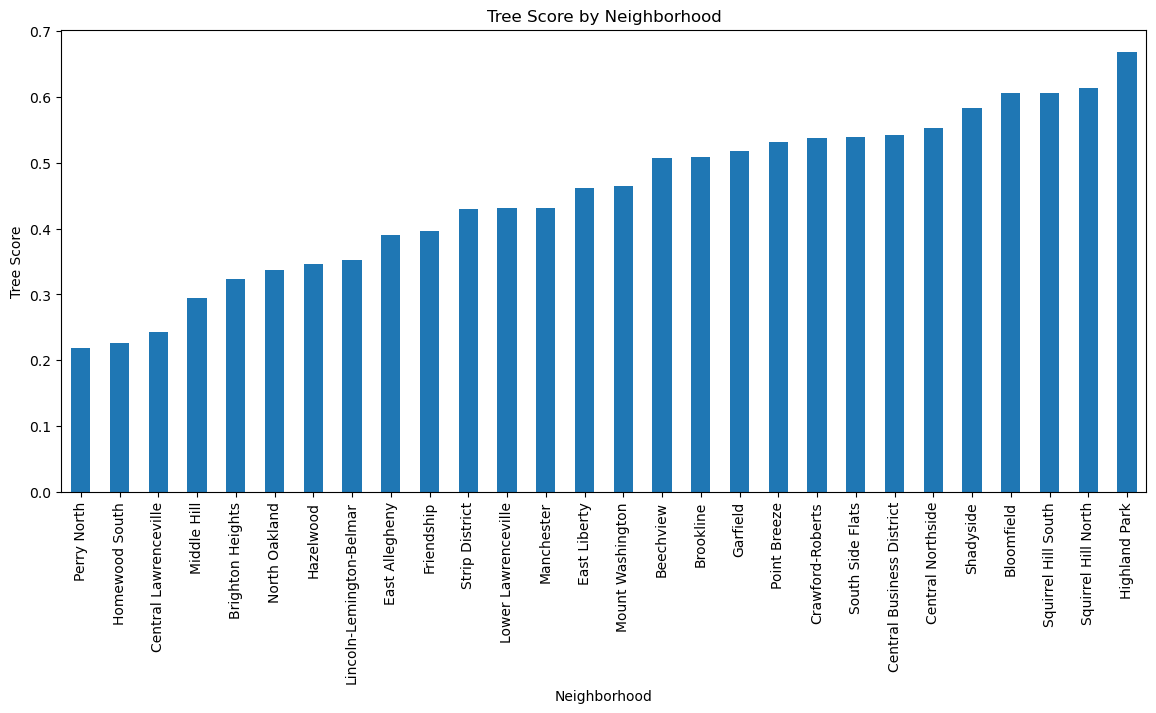

In [9]:
sorted_data.plot(
    kind='bar',
    title="Tree Score by Neighborhood",
    xlabel="Neighborhood",
    ylabel="Tree Score",
    figsize=(14,6),
    rot=90
)

Here I took the 10 best ones and graphed them on a bar graph

<Axes: title={'center': 'Top 10 Best Neighborhoods (Tree Score)'}, xlabel='Neighborhood', ylabel='Tree Score'>

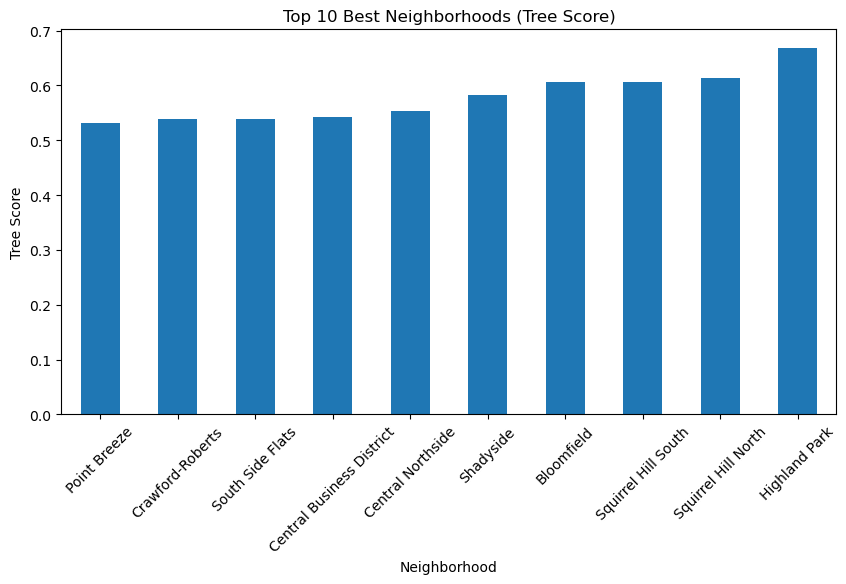

In [10]:
best10 = sorted_data.tail(10)

best10.plot(
    kind='bar',
    title="Top 10 Best Neighborhoods (Tree Score)",
    xlabel="Neighborhood",
    ylabel="Tree Score",
    figsize=(10,5),
    rot=45
)

Here I took the 10 worst ones and graphed them on a bar graph

<Axes: title={'center': 'Top 10 Worst Neighborhoods (Tree Score)'}, xlabel='Neighborhood', ylabel='Tree Score'>

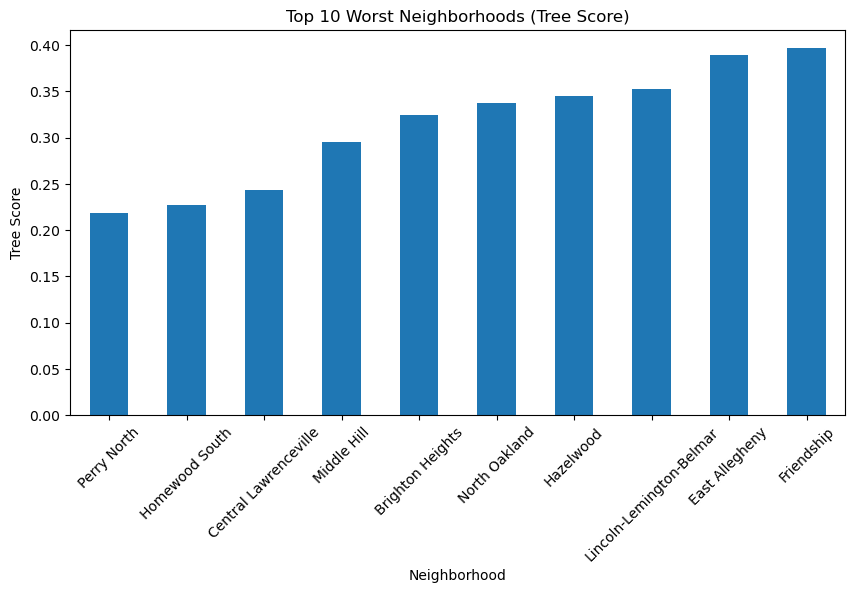

In [11]:
worst10 = sorted_data.head(10)

worst10.plot(
    kind='bar',
    title="Top 10 Worst Neighborhoods (Tree Score)",
    xlabel="Neighborhood",
    ylabel="Tree Score",
    figsize=(10,5),
    rot=45
)

## Result
By trees alone the best neighborhood is **Squirrel Hill South**, then Highland Park and Squirrel Hill North. The big neighborhoods do well on quantity, but a lot of them are only about 43% healthy, so the health part keeps the score from being a pure size contest.